<a href="https://colab.research.google.com/github/josemartinlabarca/mineria-datos-churn-telco/blob/main/lab-01-eda-precios-viviendas/Lab01_EDA_Labarca_jose.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Identificación de la fuente de datos

Nombre del dataset: House price prediction

Autor o publicador: shree1992

Enlace: https://www.kaggle.com/datasets/shree1992/housedata?resource=download

Archivo seleccionado: data.csv

Unidad de análisis: cada fila representa un registro de una propiedad o vivienda dentro del conjunto de datos de ventas inmobiliarias.

Justificación: elegí esta fuente porque contiene información sobre propiedades y sus características, permitiendo realizar un análisis exploratorio de variables relacionadas con viviendas y precios. Además, el dataset contiene múltiples variables que permiten estudiar distribuciones, valores faltantes, posibles valores extremos y relaciones entre características de las propiedades.

Pregunta inicial: me interesa explorar cómo se distribuyen los precios de las viviendas y cómo se relacionan con características como el tamaño, la ubicación y otras características de las propiedades.

Licencia o condiciones de uso: Kaggle muestra actualmente la licencia como "Unknown". Por lo tanto, no se asigna una licencia específica que no esté indicada en la fuente.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid")

print("Librerias cargadas correctamente")


Librerias cargadas correctamente


In [ ]:
from google.colab import files

archivos_subidos = files.upload()

nombre_csv = next(iter(archivos_subidos))

print("Archivo seleccionado:", nombre_csv)


Saving data precio de viviendas.csv to data precio de viviendas (1).csv
Archivo seleccionado: data precio de viviendas (1).csv


In [ ]:
df = pd.read_csv(nombre_csv)

print("Dataset cargado correctamente")

df.head()


Dataset cargado correctamente


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,"313,000.00",3.00,1.50,1340,7912,1.50,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,2014-05-02 00:00:00,"2,384,000.00",5.00,2.50,3650,9050,2.00,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,2014-05-02 00:00:00,"342,000.00",3.00,2.00,1930,11947,1.00,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA
3,2014-05-02 00:00:00,"420,000.00",3.00,2.25,2000,8030,1.00,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA
4,2014-05-02 00:00:00,"550,000.00",4.00,2.50,1940,10500,1.00,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA


In [ ]:
filas, columnas = df.shape

print("Cantidad de filas:", filas)
print("Cantidad de columnas:", columnas)


Cantidad de filas: 4600
Cantidad de columnas: 18


In [ ]:
filas, columnas = df.shape

print("Cantidad de filas:", filas)
print("Cantidad de columnas:", columnas)



Cantidad de filas: 4600
Cantidad de columnas: 18


In [ ]:
display(df.head())

display(df.tail())

display(df.sample(n=min(5, len(df)), random_state=42))


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,"313,000.00",3.00,1.50,1340,7912,1.50,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,2014-05-02 00:00:00,"2,384,000.00",5.00,2.50,3650,9050,2.00,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,2014-05-02 00:00:00,"342,000.00",3.00,2.00,1930,11947,1.00,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA
3,2014-05-02 00:00:00,"420,000.00",3.00,2.25,2000,8030,1.00,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA
4,2014-05-02 00:00:00,"550,000.00",4.00,2.50,1940,10500,1.00,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
4595,2014-07-09 00:00:00,"308,166.67",3.00,1.75,1510,6360,1.00,0,0,4,1510,0,1954,1979,501 N 143rd St,Seattle,WA 98133,USA
4596,2014-07-09 00:00:00,"534,333.33",3.00,2.50,1460,7573,2.00,0,0,3,1460,0,1983,2009,14855 SE 10th Pl,Bellevue,WA 98007,USA
4597,2014-07-09 00:00:00,"416,904.17",3.00,2.50,3010,7014,2.00,0,0,3,3010,0,2009,0,759 Ilwaco Pl NE,Renton,WA 98059,USA
4598,2014-07-10 00:00:00,"203,400.00",4.00,2.00,2090,6630,1.00,0,0,3,1070,1020,1974,0,5148 S Creston St,Seattle,WA 98178,USA
4599,2014-07-10 00:00:00,"220,600.00",3.00,2.50,1490,8102,2.00,0,0,4,1490,0,1990,0,18717 SE 258th St,Covington,WA 98042,USA


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
3683,2014-06-30 00:00:00,"544,000.00",3.00,2.50,1460,1613,2.00,0,0,3,1180,280,2007,0,6710 Alonzo Ave NW,Seattle,WA 98117,USA
4411,2014-05-22 00:00:00,0.00,5.00,2.25,2000,7900,1.00,0,0,4,1300,700,1986,0,3202 S 194th St,SeaTac,WA 98188,USA
2584,2014-06-16 00:00:00,"1,712,500.00",3.00,3.25,2940,5432,3.00,0,3,4,2440,500,1978,2000,150 Highland Dr,Seattle,WA 98109,USA
69,2014-05-04 00:00:00,"365,000.00",3.00,2.50,2200,7350,1.00,0,0,5,1570,630,1988,0,13420 SE 182nd St,Renton,WA 98058,USA
1844,2014-06-04 00:00:00,"275,000.00",3.00,2.50,1720,8755,1.00,0,0,3,1000,720,1983,2009,31607 45th Pl SW,Federal Way,WA 98023,USA


In [ ]:
print("Columnas disponibles:")

for numero, columna in enumerate(df.columns, start=1):
    print(numero, "-", columna)


Columnas disponibles:
1 - date
2 - price
3 - bedrooms
4 - bathrooms
5 - sqft_living
6 - sqft_lot
7 - floors
8 - waterfront
9 - view
10 - condition
11 - sqft_above
12 - sqft_basement
13 - yr_built
14 - yr_renovated
15 - street
16 - city
17 - statezip
18 - country


In [ ]:
df.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           4600 non-null   object 
 1   price          4600 non-null   float64
 2   bedrooms       4600 non-null   float64
 3   bathrooms      4600 non-null   float64
 4   sqft_living    4600 non-null   int64  
 5   sqft_lot       4600 non-null   int64  
 6   floors         4600 non-null   float64
 7   waterfront     4600 non-null   int64  
 8   view           4600 non-null   int64  
 9   condition      4600 non-null   int64  
 10  sqft_above     4600 non-null   int64  
 11  sqft_basement  4600 non-null   int64  
 12  yr_built       4600 non-null   int64  
 13  yr_renovated   4600 non-null   int64  
 14  street         4600 non-null   object 
 15  city           4600 non-null   object 
 16  statezip       4600 non-null   object 
 17  country        4600 non-null   object 
dtypes: float

In [ ]:
resumen_columnas = pd.DataFrame({
    "tipo_pandas": df.dtypes.astype(str),
    "datos_presentes": df.notna().sum(),
    "datos_nulos": df.isna().sum(),
    "valores_unicos": df.nunique(dropna=True)
})

display(resumen_columnas)


,tipo_pandas,datos_presentes,datos_nulos,valores_unicos
date,object,4600,0,70
price,float64,4600,0,1741
bedrooms,float64,4600,0,10
bathrooms,float64,4600,0,26
sqft_living,int64,4600,0,566
sqft_lot,int64,4600,0,3113
floors,float64,4600,0,6
waterfront,int64,4600,0,2
view,int64,4600,0,5
condition,int64,4600,0,5


In [ ]:
columnas_numericas = df.select_dtypes(
    include=np.number
).columns.tolist()

columnas_categoricas = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Columnas numericas:")
print(columnas_numericas)

print("\nColumnas categoricas:")
print(columnas_categoricas)


Columnas numericas:
['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated']

Columnas categoricas:
['date', 'street', 'city', 'statezip', 'country']


In [ ]:
resumen_nulos = pd.DataFrame({
    "cantidad_nulos": df.isnull().sum(),
    "porcentaje_nulos": (df.isnull().mean() * 100).round(2)
})

resumen_nulos = resumen_nulos.sort_values(
    by="porcentaje_nulos",
    ascending=False
)

display(resumen_nulos)


,cantidad_nulos,porcentaje_nulos
date,0,0.00
price,0,0.00
bedrooms,0,0.00
bathrooms,0,0.00
sqft_living,0,0.00
sqft_lot,0,0.00
floors,0,0.00
waterfront,0,0.00
view,0,0.00
condition,0,0.00


In [ ]:
columnas_con_nulos = resumen_nulos[
    resumen_nulos["cantidad_nulos"] > 0
]

display(columnas_con_nulos)


,cantidad_nulos,porcentaje_nulos


In [ ]:
cantidad_duplicados = df.duplicated().sum()

porcentaje_duplicados = cantidad_duplicados / len(df) * 100

print("Filas duplicadas:", cantidad_duplicados)
print("Porcentaje duplicado:", round(porcentaje_duplicados, 2), "%")


Filas duplicadas: 0
Porcentaje duplicado: 0.0 %


In [ ]:
df[df.duplicated(keep=False)].head(10)


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country


In [ ]:
valores_diferentes = df.nunique(dropna=False).sort_values()

display(valores_diferentes)


,0
country,1
waterfront,2
condition,5
view,5
floors,6
bedrooms,10
bathrooms,26
city,44
yr_renovated,60
date,70


In [ ]:
print(columnas_numericas)


['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated']


In [ ]:
if columnas_numericas:
    resumen_numerico = df[columnas_numericas].describe().T
    display(resumen_numerico)
else:
    print("El dataset no tiene columnas numericas detectadas")


,count,mean,std,min,25%,50%,75%,max
price,"4,600.00","551,962.99","563,834.70",0.00,"322,875.00","460,943.46","654,962.50","26,590,000.00"
bedrooms,"4,600.00",3.40,0.91,0.00,3.00,3.00,4.00,9.00
bathrooms,"4,600.00",2.16,0.78,0.00,1.75,2.25,2.50,8.00
sqft_living,"4,600.00","2,139.35",963.21,370.00,"1,460.00","1,980.00","2,620.00","13,540.00"
sqft_lot,"4,600.00","14,852.52","35,884.44",638.00,"5,000.75","7,683.00","11,001.25","1,074,218.00"
floors,"4,600.00",1.51,0.54,1.00,1.00,1.50,2.00,3.50
waterfront,"4,600.00",0.01,0.08,0.00,0.00,0.00,0.00,1.00
view,"4,600.00",0.24,0.78,0.00,0.00,0.00,0.00,4.00
condition,"4,600.00",3.45,0.68,1.00,3.00,3.00,4.00,5.00
sqft_above,"4,600.00","1,827.27",862.17,370.00,"1,190.00","1,590.00","2,300.00","9,410.00"


In [ ]:
comparacion_centro = pd.DataFrame({
    "media": df[columnas_numericas].mean(),
    "mediana": df[columnas_numericas].median(),
    "desviacion_estandar": df[columnas_numericas].std(),
    "minimo": df[columnas_numericas].min(),
    "maximo": df[columnas_numericas].max()
})

display(comparacion_centro)


,media,mediana,desviacion_estandar,minimo,maximo
price,"551,962.99","460,943.46","563,834.70",0.00,"26,590,000.00"
bedrooms,3.40,3.00,0.91,0.00,9.00
bathrooms,2.16,2.25,0.78,0.00,8.00
sqft_living,"2,139.35","1,980.00",963.21,370.00,"13,540.00"
sqft_lot,"14,852.52","7,683.00","35,884.44",638.00,"1,074,218.00"
floors,1.51,1.50,0.54,1.00,3.50
waterfront,0.01,0.00,0.08,0.00,1.00
view,0.24,0.00,0.78,0.00,4.00
condition,3.45,3.00,0.68,1.00,5.00
sqft_above,"1,827.27","1,590.00",862.17,370.00,"9,410.00"


In [ ]:
tabla_percentiles = df[columnas_numericas].quantile(
    [0.00, 0.05, 0.25, 0.50, 0.75, 0.95, 1.00]
).T

tabla_percentiles.columns = [
    "min",
    "p05",
    "p25",
    "p50_mediana",
    "p75",
    "p95",
    "max"
]

display(tabla_percentiles)


,min,p05,p25,p50_mediana,p75,p95,max
price,0.00,"200,000.00","322,875.00","460,943.46","654,962.50","1,184,050.00","26,590,000.00"
bedrooms,0.00,2.00,3.00,3.00,4.00,5.00,9.00
bathrooms,0.00,1.00,1.75,2.25,2.50,3.50,8.00
sqft_living,370.00,950.00,"1,460.00","1,980.00","2,620.00","3,870.00","13,540.00"
sqft_lot,638.00,"1,690.80","5,000.75","7,683.00","11,001.25","43,560.00","1,074,218.00"
floors,1.00,1.00,1.00,1.50,2.00,2.00,3.50
waterfront,0.00,0.00,0.00,0.00,0.00,0.00,1.00
view,0.00,0.00,0.00,0.00,0.00,2.00,4.00
condition,1.00,3.00,3.00,3.00,4.00,5.00,5.00
sqft_above,370.00,860.00,"1,190.00","1,590.00","2,300.00","3,440.00","9,410.00"


In [ ]:
print(columnas_categoricas)


['date', 'street', 'city', 'statezip', 'country']


In [ ]:
columna_categorica = columnas_categoricas[0]

print("Columna elegida:", columna_categorica)


Columna elegida: date


In [ ]:
frecuencia = df[columna_categorica].value_counts(
    dropna=False
)

porcentaje = df[columna_categorica].value_counts(
    dropna=False,
    normalize=True
).mul(100).round(2)

tabla_frecuencias = pd.DataFrame({
    "cantidad": frecuencia,
    "porcentaje": porcentaje
})

display(tabla_frecuencias.head(15))


,cantidad,porcentaje
date,,
2014-06-23 00:00:00,142,3.09
2014-06-25 00:00:00,131,2.85
2014-06-26 00:00:00,131,2.85
2014-07-08 00:00:00,127,2.76
2014-07-09 00:00:00,121,2.63
2014-06-24 00:00:00,120,2.61
2014-05-20 00:00:00,116,2.52
2014-07-01 00:00:00,116,2.52
2014-06-17 00:00:00,113,2.46


In [ ]:
columna_numerica = "NOMBRE_DE_LA_VARIABLE"


In [ ]:
print(columnas_numericas)
# Cambia el indice para elegir una variable significativa.
columna_numerica = columnas_numericas[0]
print("Columna elegida:", columna_numerica)



['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated']
Columna elegida: price


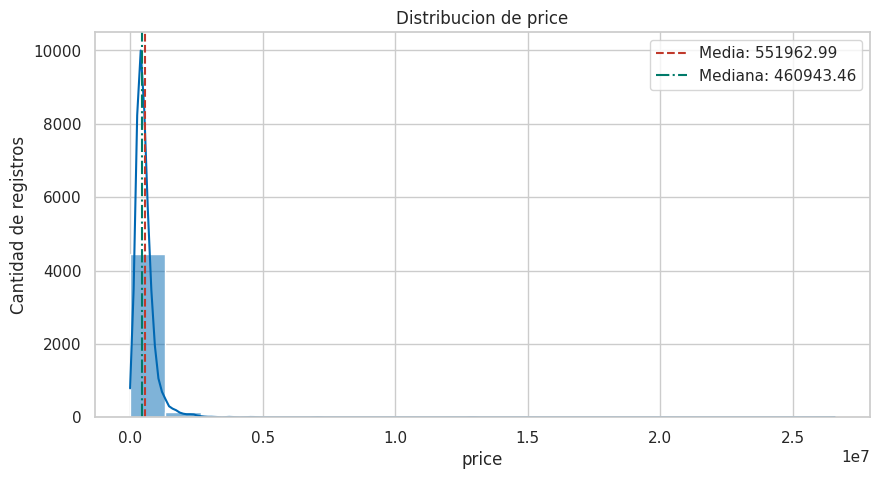

In [ ]:
media = df[columna_numerica].mean()
mediana = df[columna_numerica].median()

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x=columna_numerica,
    bins=20,
    kde=True,
    color="#0068B3"
)

plt.axvline(
    media,
    color="#C0392B",
    linestyle="--",
    label=f"Media: {media:.2f}"
)

plt.axvline(
    mediana,
    color="#007A6A",
    linestyle="-.",
    label=f"Mediana: {mediana:.2f}"
)

plt.title(f"Distribucion de {columna_numerica}")
plt.xlabel(columna_numerica)
plt.ylabel("Cantidad de registros")
plt.legend()

plt.show()


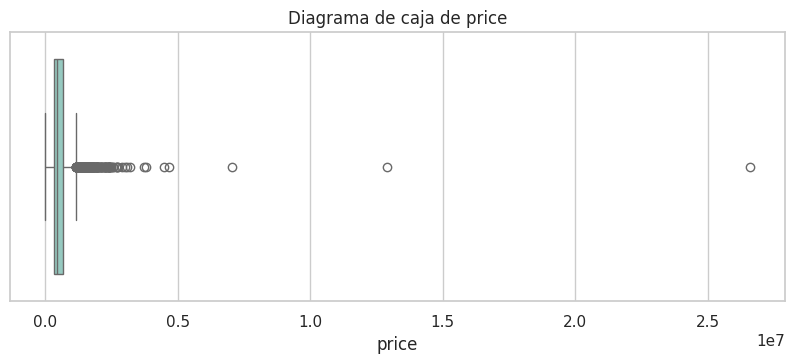

In [ ]:
plt.figure(figsize=(10, 3.5))

sns.boxplot(
    x=df[columna_numerica],
    color="#8ED1C6"
)

plt.title(f"Diagrama de caja de {columna_numerica}")
plt.xlabel(columna_numerica)

plt.show()


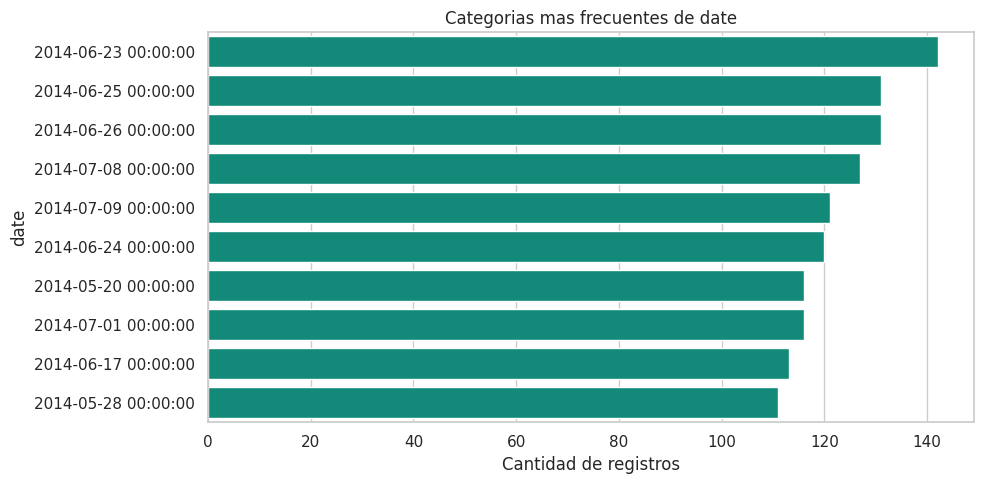

In [ ]:
top_categorias = df[columna_categorica].value_counts(
    dropna=False
).head(10)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=top_categorias.values,
    y=top_categorias.index.astype(str),
    color="#009C88"
)

plt.title(f"Categorias mas frecuentes de {columna_categorica}")
plt.xlabel("Cantidad de registros")
plt.ylabel(columna_categorica)

plt.tight_layout()

plt.show()


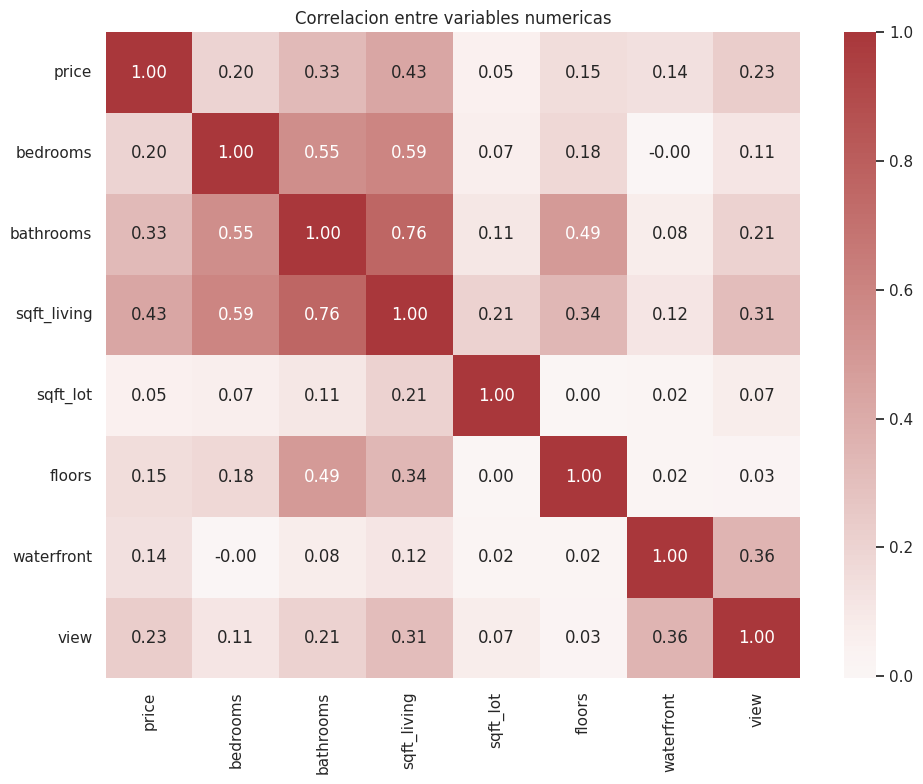

In [ ]:
seleccion_correlacion = columnas_numericas[:8]

if len(seleccion_correlacion) >= 2:

    matriz_correlacion = df[seleccion_correlacion].corr()

    plt.figure(figsize=(10, 8))

    sns.heatmap(
        matriz_correlacion,
        annot=True,
        fmt=".2f",
        cmap="vlag",
        center=0
    )

    plt.title("Correlacion entre variables numericas")
    plt.tight_layout()

    plt.show()


Hallazgos principales
1. Tamaño y unidad de análisis

El dataset utilizado corresponde a House price prediction, publicado en Kaggle por shree1992. El archivo analizado es data.csv y contiene [X] filas y [Y] columnas. Cada fila representa un registro asociado a una propiedad o vivienda dentro del conjunto de datos. Esta estructura permite realizar un análisis exploratorio de las características de las propiedades y de las variables relacionadas con sus precios.

Pregunta pendiente: sería necesario revisar con mayor detalle la documentación de la fuente para determinar exactamente cómo fueron recopilados los registros y cuál es el periodo temporal que representan.

2. Tipos de columnas

El análisis identificó [X] variables numéricas y [Y] variables categóricas. Entre las variables numéricas se encuentran aquellas relacionadas con características cuantitativas de las viviendas, mientras que las variables categóricas permiten diferenciar determinados grupos o características de las propiedades.

Los tipos detectados por pandas corresponden a la representación técnica de los datos, por lo que deben interpretarse considerando también el significado de cada variable.

Pregunta pendiente: es necesario verificar en la documentación de Kaggle el significado y las unidades de las variables más importantes antes de utilizarlas para análisis posteriores.

3. Valores nulos

El análisis de valores faltantes encontró [X] valores nulos en total, correspondientes a [Y] % de las observaciones, distribuidos principalmente en las columnas [nombre de columna o columnas].

Estos valores no deben interpretarse automáticamente como cero, ausencia de una característica o un valor inválido. Su significado depende de cómo fueron recopilados los datos.

Pregunta pendiente: antes de realizar una imputación o eliminar registros, es necesario consultar la documentación y determinar por qué se producen estos valores faltantes.

4. Duplicados

Se encontraron [X] filas duplicadas, equivalentes al [Y] % del dataset.

La existencia de filas idénticas no implica necesariamente que los datos sean incorrectos. Podrían representar registros repetidos o, dependiendo de la unidad de análisis, observaciones que coinciden en todas las variables disponibles.

Pregunta pendiente: antes de eliminar estos registros se debería verificar cómo se identifica de manera única una propiedad o transacción y determinar si los duplicados representan errores de registro.

5. Distribución numérica

La variable [nombre de variable] presenta una media de [X] y una mediana de [Y]. La diferencia entre ambas medidas indica que la distribución podría presentar cierto grado de asimetría.

Además, el rango observado se encuentra entre [mínimo] y [máximo], lo que muestra una variabilidad importante entre las propiedades registradas.

El histograma y el diagrama de caja permiten observar la concentración de los valores y posibles observaciones alejadas del comportamiento central.

Pregunta pendiente: sería necesario revisar los valores extremos para determinar si corresponden a propiedades reales con características particulares o a posibles problemas de calidad de datos.

6. Distribución de categorías

La variable categórica [nombre de columna] presenta como categoría más frecuente [categoría], con [cantidad] registros, equivalentes al [porcentaje] % del dataset.

La distribución muestra que [existe una categoría dominante / las categorías presentan una distribución relativamente equilibrada].

Esta diferencia puede ser relevante para futuros análisis, especialmente si posteriormente se construye un modelo que utilice esta variable.

Pregunta pendiente: se debería verificar si las categorías están correctamente estandarizadas y si existen diferencias de escritura o valores que representen conceptualmente la misma categoría.

7. Posibles valores extremos

El diagrama de caja de [variable] muestra [X] observaciones potencialmente alejadas de la concentración principal de los datos.

Estos valores no deben considerarse automáticamente errores, ya que en un dataset inmobiliario podrían existir viviendas con características o precios considerablemente diferentes del promedio.

Pregunta pendiente: es necesario revisar estas observaciones y contrastarlas con la documentación de la fuente antes de decidir si deben conservarse, transformarse o excluirse.

Conclusión sobre la utilidad del dataset

El dataset House price prediction resulta útil para realizar un análisis exploratorio de propiedades inmobiliarias y estudiar descriptivamente cómo se distribuyen los precios y cómo se relacionan con diferentes características de las viviendas. Entre sus principales fortalezas se encuentra la cantidad y variedad de variables disponibles, que permiten analizar medidas de tendencia central, dispersión, percentiles, categorías y relaciones entre variables. El EDA también permitió identificar valores nulos, posibles duplicados y observaciones potencialmente extremas. Sin embargo, antes de utilizar el dataset para construir un modelo predictivo sería necesario investigar el significado exacto de cada variable, sus unidades, el origen y periodo de los datos, el tratamiento adecuado de los valores faltantes y la naturaleza de los posibles valores extremos. También sería importante verificar que las variables representen correctamente la pregunta que se desea responder y que no existan problemas de calidad o sesgos en la información. Por lo tanto, el dataset es apropiado como punto de partida para un análisis exploratorio, pero requiere validaciones adicionales antes de pasar a las etapas de preparación y modelado.

Relación con CRISP-DM

El trabajo realizado en este laboratorio corresponde principalmente a la fase de Comprensión de los Datos (Data Understanding) de la metodología CRISP-DM. En primer lugar, se revisó la procedencia del dataset House price prediction, identificando su publicación en Kaggle, el autor, el archivo utilizado y la unidad de análisis. Posteriormente se examinó la estructura del dataset mediante shape(), head(), tail(), sample() e info(), permitiendo conocer la cantidad de registros, variables y tipos de datos presentes.

También se realizó una evaluación inicial de la calidad de los datos mediante el análisis de valores nulos, porcentajes de datos faltantes, filas duplicadas y cantidad de valores distintos por columna. Además, se identificaron las variables numéricas y categóricas disponibles y se calcularon estadísticas descriptivas como media, mediana, desviación estándar, valores mínimos, máximos y percentiles. Las visualizaciones mediante histogramas, diagramas de caja y gráficos de barras permitieron comprender mejor las distribuciones de las variables y detectar posibles valores extremos. Finalmente, el análisis de correlación permitió explorar asociaciones lineales entre algunas variables numéricas.

Por estas razones, el laboratorio se concentra principalmente en Data Understanding, ya que el objetivo fue conocer la fuente, estructura, calidad, distribución y relaciones iniciales de los datos. Todavía no se ha realizado una etapa completa de preparación de datos ni de construcción de modelos. Las preguntas pendientes identificadas durante el análisis deberán resolverse antes de transformar los datos o utilizarlos para realizar predicciones.

## Aplicación de CRISP-DM

### 1. Comprensión del Negocio (Business Understanding)
El objetivo analítico se centra en estudiar el dataset de predicción de precios de viviendas para identificar qué características físicas y locativas influyen de manera determinante en el valor comercial de una propiedad. Esto permite alinear el análisis exploratorio con la necesidad de entender el mercado inmobiliario local, estableciendo bases claras para estimar precios de manera objetiva.

### 2. Comprensión de los Datos (Data Understanding)
Se cargó y exploró la estructura del archivo `data.csv`, el cual cuenta con 4,600 filas y 18 columnas (como `price`, `sqft_living`, `bedrooms`, `city`, entre otras). A través del análisis exploratorio (EDA) se revisaron tipos de datos, resúmenes estadísticos, histogramas y matrices de correlación, verificando que no existieran registros duplicados y conociendo la distribución de los precios y tamaños.

### 3. Preparación de los Datos (Data Preparation)
A partir de las revisiones iniciales, esta fase contemplará la limpieza de posibles valores atípicos en variables de superficie o precio extremo, la conversión de tipos de datos si es necesario (como el campo de fechas), y la codificación de variables geográficas o categóricas (`city`, `statezip`) para dejar el conjunto de datos óptimo para futuros modelos.

### 4. Modelamiento (Modeling)
Dado que esta etapa es una propuesta metodológica para fases futuras, se proyecta el uso de algoritmos de regresión supervisada (como Regresión Lineal o modelos basados en árboles de decisión) utilizando variables predictoras clave como el metraje habitable (`sqft_living`) y la cantidad de baños o habitaciones para estimar el precio (`price`).

### 5. Evaluación (Evaluation)
La evaluación del rendimiento de los futuros modelos se medirá utilizando métricas cuantitativas estándar de regresión, tales como el Error Cuadrático Medio (MSE) o el Coeficiente de Determinación ($R^2$), validando si el modelo explica adecuadamente la variabilidad de los precios de las viviendas y cumple con el objetivo de negocio planteado.

### 6. Despliegue (Deployment)
Como cierre del ciclo, el resultado analítico y los modelos validados se documentarán de forma reproducible mediante este mismo repositorio en GitHub y Google Colab. A futuro, este flujo podría integrarse en una herramienta interactiva o dashboard web para que usuarios o tasadores consulten estimaciones de precios en tiempo real.